# Homework 4: Evaluation

Questions: [ML Zoomcamp 2026 – Homework 4](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md)

Dataset: [2026 Course Lead Scoring](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)

Goal: predict `converted` (whether the client signed up to the platform) and evaluate the model with ROC AUC, precision/recall, F1 and cross-validation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, train_test_split

## Data preparation

Check for missing values. Fill categorical features with `'NA'` and numerical features with `0.0`.

In [2]:
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]
features = categorical + numerical
target = "converted"

df = pd.read_csv("data/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)
df.isnull().sum().sum()

np.int64(0)

## Split the data

Use the exact `train_test_split` calls from the homework (60/20/20, `random_state=1`).

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train[target].values
y_val = df_val[target].values

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Q1. ROC AUC feature importance

Use each numerical variable as a score and compute AUC against `converted` on the training set. If AUC < 0.5, negate the variable. Which has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [6]:
aucs = {}
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    aucs[col] = auc

pd.Series(aucs).sort_values(ascending=False).round(4)

lead_score                  0.7882
interaction_count           0.7649
number_of_courses_viewed    0.7230
annual_income               0.6082
dtype: float64

**Answer:** `lead_score` (0.788)

None of the variables needed negating — all are positively associated with conversion.

## Q2. Training the model

One-hot encode with `DictVectorizer`, fit `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)` on train, and report validation AUC rounded to 3 digits.

- 0.532
- 0.632
- 0.732
- 0.832

In [7]:
def train(df, y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df[features].to_dict(orient="records"))
    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model


def predict(df, dv, model):
    X = dv.transform(df[features].to_dict(orient="records"))
    return model.predict_proba(X)[:, 1]

In [8]:
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
round(roc_auc_score(y_val, y_pred), 3)

0.732

**Answer:** 0.732

## Q3. Precision and recall

Compute precision and recall on validation for thresholds 0.0 to 1.0 (step 0.01) and plot them. Ignoring thresholds where both are zero, at which threshold is `|precision - recall|` smallest?

- 0.43
- 0.63
- 0.73
- 0.83

In [9]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)

rows = []
for t in thresholds:
    predicted = y_pred >= t
    tp = (predicted & (y_val == 1)).sum()
    fp = (predicted & (y_val == 0)).sum()
    fn = (~predicted & (y_val == 1)).sum()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    rows.append((t, precision, recall))

scores = pd.DataFrame(rows, columns=["threshold", "precision", "recall"])

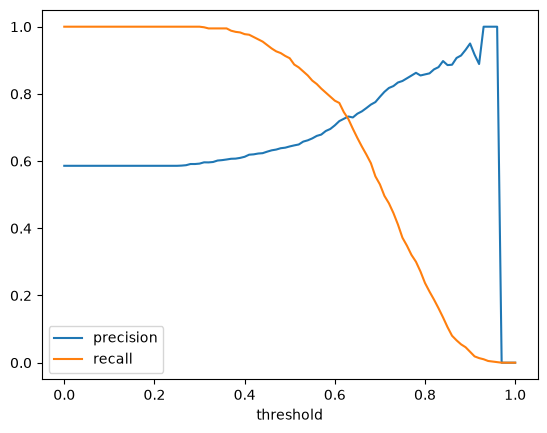

In [10]:
plt.plot(scores.threshold, scores.precision, label="precision")
plt.plot(scores.threshold, scores.recall, label="recall")
plt.xlabel("threshold")
plt.legend()
plt.show()

In [11]:
nonzero = scores[(scores.precision > 0) | (scores.recall > 0)]
diff = (nonzero.precision - nonzero.recall).abs()
nonzero.loc[diff.nsmallest(3).index]

,threshold,precision,recall
63,0.63,0.732759,0.725256
62,0.62,0.725914,0.745734
64,0.64,0.729875,0.696246


**Answer:** 0.63 (precision 0.733, recall 0.725)

## Q4. F1 score

Compute $F_1 = 2 \cdot \frac{P \cdot R}{P + R}$ for every threshold. At which threshold is F1 maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [12]:
p, r = scores.precision, scores.recall
scores["f1"] = (2 * p * r / (p + r)).fillna(0.0)
scores.loc[scores.f1.nlargest(3).index]

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032


**Answer:** 0.41 (F1 0.758)

The optimum sits well below 0.5 because ~59% of validation leads convert: a low threshold buys near-perfect recall while precision only drops toward the base rate.

## Q5. 5-Fold CV

Run `KFold(n_splits=5, shuffle=True, random_state=1)` over `df_full_train`, train on each train fold, score AUC on each validation fold. What's the standard deviation of the scores?

- 0.001
- 0.007
- 0.013
- 0.060

In [13]:
def cv_scores(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv, model = train(df_tr, df_tr[target].values, C=C)
        scores.append(roc_auc_score(df_va[target], predict(df_va, dv, model)))
    return np.array(scores)

In [14]:
auc_folds = cv_scores()
auc_folds.round(3), round(auc_folds.std(), 3)

(array([0.731, 0.73 , 0.736, 0.741, 0.721]), np.float64(0.007))

**Answer:** 0.007

## Q6. Hyperparameter tuning

Same 5-fold CV for `C` in `[0.000001, 0.001, 1]`; round mean and std to 3 digits. Pick the best mean, breaking ties by lowest std, then smallest `C`.

- 0.000001
- 0.001
- 1

In [15]:
for C in [0.000001, 0.001, 1]:
    s = cv_scores(C=C)
    print(f"C={C}: mean={s.mean():.3f} std={s.std():.3f}")

C=1e-06: mean=0.617 std=0.019
C=0.001: mean=0.749 std=0.010


C=1: mean=0.732 std=0.007


**Answer:** 0.001 (mean 0.749 ± 0.010)

Stronger regularization helps here: `annual_income` is unscaled, so with `C=1` it dominates the coefficients (dropping it lifts CV AUC at `C=1` to 0.791). `C=1e-6` overshoots and shrinks everything toward zero.

## Summary

| Question | Answer |
|---|---|
| Q1. Highest-AUC numerical variable | `lead_score` |
| Q2. Validation AUC | 0.732 |
| Q3. Precision/recall intersection | 0.63 |
| Q4. Max F1 threshold | 0.41 |
| Q5. CV std of AUC | 0.007 |
| Q6. Best `C` | 0.001 |